# Auto Pitting with MCTS

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from racer_rl import Track, start, transition, utils
from racer_rl import bellmax as bmx
from racer_rl.track import wrap_to_pi

## MCTS Implementation

Here we will implement a class inheirt from `bellmax` for our pitting task

In [ ]:
track = Track.from_name("laguna_seca_pit") 


class PitStop(bmx.MCTS):
    def __init__(self, num_sim=1000, max_depth=16, exploration_coefficient=100.0):
        super().__init__(max_depth=max_depth, num_sim=num_sim)
        self.exploration_coefficient = exploration_coefficient
        # TODO Define some discretized action space for the control with spacing (Delta u) of your choice
        self.steerings = jnp.array(None)
        self.pedals = jnp.array(None)
        # do you need somethin else?
        self.steps = 10  # an action chunk for 1 second

    # "path" is sorta like doing temporal discretization
    # the next state is from doing zero order hold on the action you provide at the current state
    def path(self, state, action):
        """The states that an action leads through."""
        # TODO: extract the control (pedal and steering) from action 
        # (trivial if action you defined is a pair of pedal and steering)
        None, None= action

        def step(state, _):
            pedal = None
            steering = None
            state = transition(track, state, jnp.stack([pedal, steering]))
            return state, state

        return jax.lax.scan(step, state, length=self.steps)[1]

    def distance(self, state, box):
        """Helper function for us to define the reward"""
        along = jnp.abs(box[0] - state.progress)
        across = jnp.abs(box[1] - state.lateral)
        turned = jnp.abs(wrap_to_pi(state.car[2] - track.heading(state.progress) - box[2]))
        return along + across + 10.0 * turned

    def transition(self, state, action):
        return jax.tree.map(lambda x: x[-1], self.path(state, action))

    def actions(self, state):
        # TODO Return the discretized action space for the control
        # return jax.Array of shape (N, 2) where N is the number of action pairs
        # Hint: jnp.meshgrid, jnp.stack can be useful
        return None

    def expand(self, key, state, actions):
        # The Expansion Phase: randomly select an action to expand
        return jax.random.randint(key, (), 0, len(actions))

    def rollout(self, key, state, actions):
        # The Simulation Phase: randomly select an action to simulate
        return jax.random.randint(key, (), 0, len(actions))
    
    def reward(self, state, action, next_state, box):
        # Optional TODO, you can try different reward shaping strategies
        crashed = ~next_state.on_track
        return -(self.distance(next_state, box) + 30.0 * crashed).astype(jnp.float32)

    def terminal(self, state, box):
        return (self.distance(state, box) < 2.0) & (state.car[3] < 1.0)

    def select(self, key, state, actions, visits, values):
        # The Selection Phase: choose the action with the highest UCB1 score
        # TODO
        # Hint: jnp.argmax can be handy
        return None


origin = start(track, progress=3260.0, speed=12.0)  # in the pit lane
box = jnp.array([3360.0, -1.0, 0.0])
key = jax.random.key(42)
search = PitStop()
scene = utils.Scene(track, first=3250.0, last=3380.0, box=box)


# Start State
AKA the root node

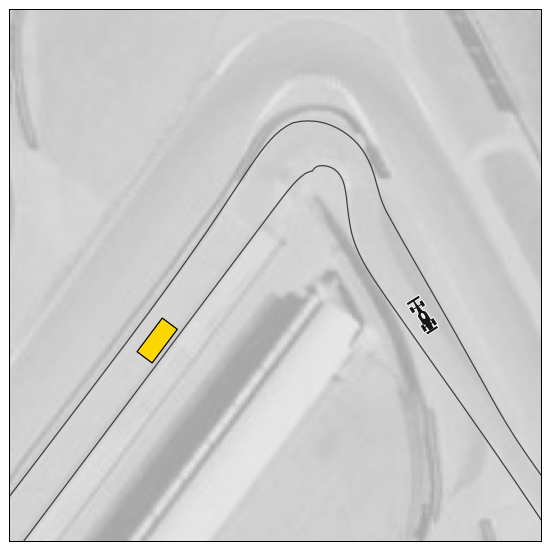

In [3]:
fig, ax = plt.subplots(figsize=(6, 6), dpi=90, layout="constrained")
scene.draw(ax, origin.car)
plt.show()

# The (discretized) actions
Here we visualize all the possible (discretized) action chunks (ZOH of action over a fixed time horizion)

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6), dpi=90, layout="constrained")
scene.draw(ax, origin.car, center=origin.car[:2], reach=30.0)

for action in search.actions(origin):
    path = np.asarray(search.path(origin, action).car[:, :2])
    path = np.vstack([origin.car[:2], path])
    ax.plot(*path.T, color="C1", lw=3)
    ax.scatter(*path[-1], s=50, facecolors="none", edgecolors="C1", linewidths=1.5, zorder=4)

ax.set_title("Discretized actions", fontsize=15, pad=12)
plt.show()

## Complete Search

Let's perform a full MCTS for `num_sim` rounds/simulations/rollouts


Every curve below is an action the search tried, drawn where it drives. The thicker the curve, the better the search thinks of it (its Q-value).

In [ ]:
result = search.search(key, origin, box)
values = utils.tree_values(search, result.tree)
value_scale = utils.value_scale(values)

fig, ax = plt.subplots(figsize=(6, 6), dpi=90, layout="constrained")
scene.draw_action_values(ax, values, value_scale, origin.car)
ax.set_title("Q-values from MCTS\nCurves: actions · Thicker: higher value", fontsize=15, pad=12)
plt.show()

the state value. Darker is better.

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6), dpi=90, layout="constrained")
scene.draw_state_values(ax, values, value_scale, origin.car)
ax.set_title("State values from MCTS\nBest action value at each state", fontsize=15, pad=12)
plt.show()

Watch the tree grows!

In [ ]:
simulations_per_frame = 20
snapshots = jax.device_get(utils.search_snapshots(search, key, origin, (box,), simulations_per_frame))
search_frames = []

for index in range(len(snapshots.size)):
    tree = jax.tree.map(lambda x: x[index], snapshots)
    search_frames.append((origin.car, utils.tree_values(search, tree), None))

simulation_labels = [f"Simulation {min((i + 1) * simulations_per_frame, search.num_sim)}"
                     for i in range(len(search_frames))]
scene.animate(search_frames, simulation_labels, "videos/mcts_search.mp4", interval=150)

## How many simulations, how much exploration?

More simulations grow a larger tree. The exploration factor $c$ decides how "fat" and "shallow" the tree is

In [ ]:
simulation_counts = [10, 100, 1000, 10000]
exploration_coefficients = [1.0, 30.0, 1000.0, 30000.0]
comparisons = {}

for exploration in exploration_coefficients:
    for num_sim in simulation_counts:
        outcome = PitStop(num_sim=num_sim, exploration_coefficient=exploration).search(key, origin, box)
        comparisons[exploration, num_sim] = utils.tree_values(search, outcome.tree)

comparison_scale = utils.value_scale(*comparisons.values())


def comparison_axes():
    fig, axes = plt.subplots(4, 4, figsize=(12, 12), dpi=90, layout="constrained")
    for row, exploration in enumerate(exploration_coefficients):
        for column, num_sim in enumerate(simulation_counts):
            if row == 0:
                axes[row, column].set_title(f"{num_sim:,} simulations")
            if column == 0:
                axes[row, column].set_ylabel(f"exploration = {exploration:g}")
    return fig, axes


fig, axes = comparison_axes()
for row, exploration in enumerate(exploration_coefficients):
    for column, num_sim in enumerate(simulation_counts):
        scene.draw_action_values(axes[row, column], comparisons[exploration, num_sim], comparison_scale, origin.car)
plt.show()

In [ ]:
fig, axes = comparison_axes()
for row, exploration in enumerate(exploration_coefficients):
    for column, num_sim in enumerate(simulation_counts):
        scene.draw_state_values(axes[row, column], comparisons[exploration, num_sim], comparison_scale, origin.car)
plt.show()

## Let's go home (pit)!

Usually during online deployment you dont reach the terminal state at the start nor your have enough resource to compute a large tree.

In [ ]:
replan_steps = 20  # replan every this many steps
mcts_online = PitStop(max_depth=4, num_sim=500) # remember each action is "self.steps" long, for example if self.steps = 10 then depth of 4 is 4s of future.

@jax.jit
def drive(state, action):
    """The states of the first `replan_steps` steps of an action, one every 0.1 s."""
    return jax.tree.map(lambda x: x[:replan_steps], mcts_online.path(state, action))


state = origin
driven = [np.asarray(origin.car[:2])]
planning_frames = []
max_steps = 50

for step in range(max_steps + 1):
    outcome = mcts_online.search(jax.random.fold_in(key, step), state, box)
    values = utils.tree_values(mcts_online, outcome.tree)
    planning_frames.append((state.car, values, np.asarray(driven)))
    if bool(mcts_online.terminal(state, box)) or not bool(state.on_track) or step == max_steps:
        break
    action = outcome.actions[jnp.argmax(outcome.action_visits)]
    moved = drive(state, action)
    for car in np.asarray(moved.car)[:-1]:  # the car under way, with the same tree
        driven.append(car[:2])
        planning_frames.append((car, values, np.asarray(driven)))
    state = jax.tree.map(lambda x: x[-1], moved)
    driven.append(np.asarray(state.car[:2]))

seconds = 0.1 * (len(planning_frames) - 1)
turned = np.degrees(wrap_to_pi(state.car[2] - track.heading(state.progress) - box[2]))
print(f"{'in the box' if mcts_online.terminal(state, box) else 'not in the box'} after {seconds:.1f} s, "
      f"at {state.car[3]:.1f} m/s, turned {abs(turned):.0f}° from the box")

step_labels = [f"t = {0.1 * i:.1f} s" for i in range(len(planning_frames))]
scene.animate(planning_frames, step_labels, "videos/mcts_pit_stop.mp4", interval=100)